In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb as db
import geopandas as gpd
import pyarrow as pa

In [3]:
columns_orig = ["FICO", "first_payment_date", "first_time_homebuyer", "maturity_date", "MSA", "MI_perc", "n_units",
           "occupancy_status", "CLTV", "DTI", "UPB", "LTV", "orig_interest_rate", "channel",
           "prepayment_penalty_yn", "amortization_type", "property_state", "property_type", "postal_code",
           "loan_ID", "loan_purpose", "orig_loan_term", "n_borrowers", "seller_name", "super_conforming_flag",
           "pre_harp_loan_sequence_number", "special_eligibility_program", "harp_indicator",
           "property_valuation_method", "interest_only_yn", "vantage_score"]

columns_perf = ["loan_ID", "period", "current_actual_UPB", "current_loan_delinquency_status", "loan_age", "months_to_maturity",
                "underwriting_defect_and_major_servicing_defect_settlement_date", "modification_flag", "zero_balance_code",
                "zero_balance_effective_date", "current_interest_rate", "current_non_interest_bearing_UPB", "DDLPI", "MI_recoveries", "net_sale_proceeds",
                "non_MI_recoveries", "total_expenses", "legal_costs", "maintenance_costs", "tax_and_insurance", "misc_expenses", "actual_loss",
                "cum_modification_costs", "interest_rate_step_indicator", "payment_deferral_flag", "ELTV", "zero_balance_removal_UPB",
                "delinquent_accrued_interest", "delinquency_due_to_disaster", "borrower_assistance_plan", "current_period_modification_costs",
                "current_interest_bearing_UPB", "mortgage_insurance_cancellation", "servicer_name", "bankruptcy_cramdown_costs"]

orig_str = ["MSA", "postal_code", "loan_ID", "pre_harp_loan_sequence_number"]
perf_str = ["loan_ID", "current_loan_delinquency_status", "zero_balance_code", "net_sale_proceeds"]

In [57]:
orig = {}
for year in range(2015, 2025):
    path = f"../data/sample_{year}/sample_orig_{year}.txt"
    orig[year] = pd.read_csv(
        path, sep="|", names=columns_orig, header=None,
        dtype=dict.fromkeys(orig_str, str),
    )

df_orig = pd.concat(
    (d.assign(vintage=y) for y, d in orig.items()),
    ignore_index=True,
)

In [58]:
orig[2018]

,FICO,first_payment_date,first_time_homebuyer,maturity_date,MSA,MI_perc,n_units,occupancy_status,CLTV,DTI,...,orig_loan_term,n_borrowers,seller_name,super_conforming_flag,pre_harp_loan_sequence_number,special_eligibility_program,harp_indicator,property_valuation_method,interest_only_yn,vantage_score
0,654,201803,N,204802,NaN,0,1,P,77,35,...,360,1,OTHER,N,NaN,NaN,N,7,N,9999
1,693,201803,N,203302,24340,0,1,P,80,41,...,180,2,OTHER,N,NaN,NaN,N,1,N,9999
2,757,201803,Y,204802,NaN,25,1,P,97,10,...,360,1,OTHER,N,NaN,H,N,7,N,9999
3,807,201803,N,203302,NaN,0,1,P,26,38,...,180,2,OTHER,N,NaN,NaN,N,7,N,9999
4,812,201803,N,203302,19340,0,1,P,14,14,...,180,2,OTHER,N,NaN,NaN,N,1,N,9999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,808,202002,N,205001,29420,0,1,S,78,25,...,360,2,U.S. BANK N.A.,N,NaN,NaN,N,7,N,9999
49996,703,202005,N,205004,NaN,25,1,P,86,41,...,360,2,OTHER,N,NaN,NaN,N,7,N,9999
49997,809,202008,N,203507,28940,0,1,P,22,2,...,180,1,OTHER,N,NaN,NaN,N,7,N,9999
49998,779,202010,N,205009,NaN,0,1,P,72,26,...,360,2,OTHER,N,NaN,NaN,N,7,N,9999


## Weighted Average FICO, CLTV etc

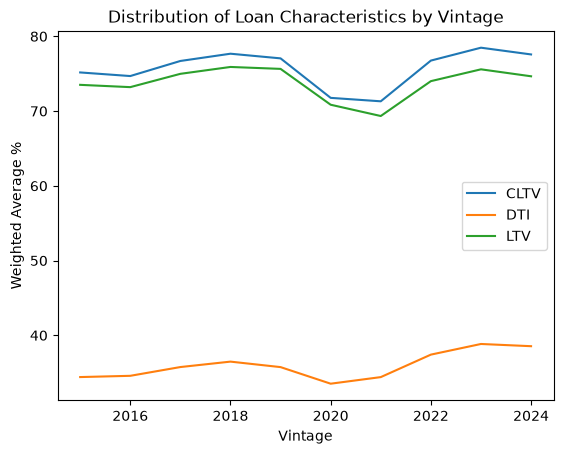

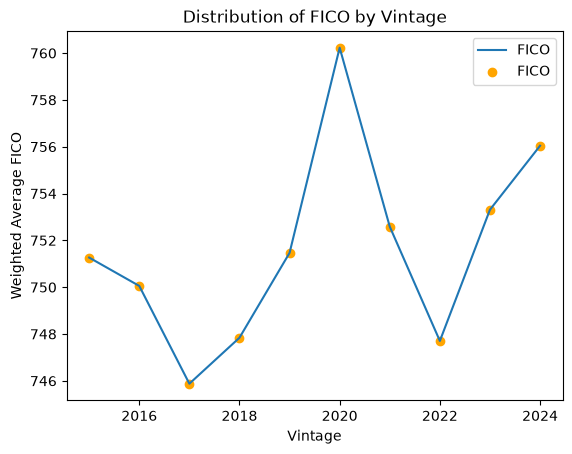

In [59]:
ok = df_orig[df_orig["FICO"].between(300, 850)]
wa_fico = (ok["FICO"] * ok["UPB"]).groupby(ok["vintage"]).sum() / ok.groupby("vintage")["UPB"].sum().to_numpy()

ok2 = df_orig[df_orig['CLTV'].between(1,998)]
wa_cltv = (ok2["CLTV"] * ok2["UPB"]).groupby(ok2["vintage"]).sum() / ok2.groupby("vintage")["UPB"].sum().to_numpy()

ok3 = df_orig[df_orig['DTI'].between(0,66)]
wa_dti = (ok3["DTI"] * ok3["UPB"]).groupby(ok3["vintage"]).sum() / ok3.groupby("vintage")["UPB"].sum().to_numpy()

ok4 = df_orig[df_orig['LTV'].between(1,998)]
ltv = ok4.groupby("vintage")["LTV"].mean().to_numpy()

plt.plot(wa_fico.index, wa_cltv, label="CLTV")
plt.plot(wa_fico.index, wa_dti, label="DTI")
plt.plot(wa_fico.index, ltv, label="LTV")
plt.xlabel("Vintage")
plt.ylabel("Weighted Average %")
plt.title("Distribution of Loan Characteristics by Vintage")
plt.legend()
plt.show()

plt.plot(wa_fico.index, wa_fico, label="FICO")
plt.scatter(wa_fico.index, wa_fico, label="FICO", color="orange")
plt.xlabel("Vintage")
plt.ylabel("Weighted Average FICO")
plt.title("Distribution of FICO by Vintage")
plt.legend()
plt.show()

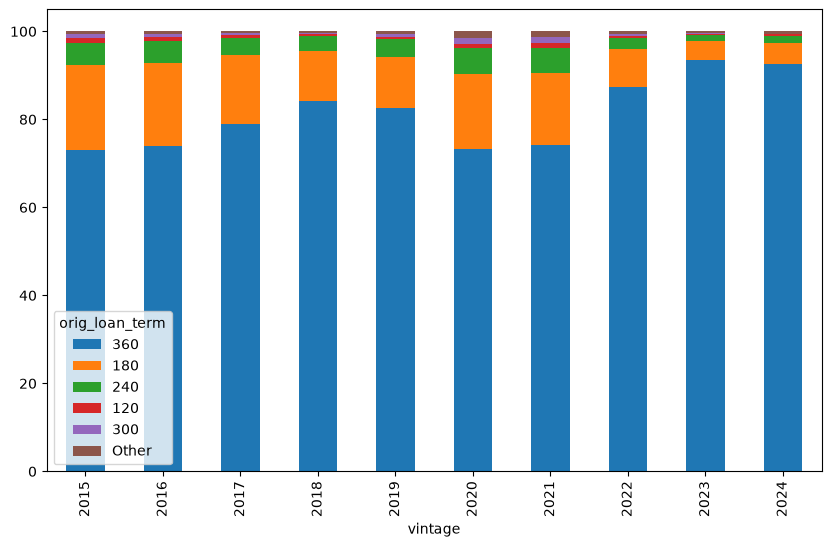

In [60]:
table_term = db.sql("""
    SELECT vintage,
       orig_loan_term,
       count(*) AS count,
       100.0 * count(*) / SUM(count(*)) OVER (PARTITION BY vintage) AS percent
FROM df_orig
GROUP BY vintage, orig_loan_term
ORDER BY vintage, count DESC
""").df()

p = table_term.pivot(index="vintage", columns="orig_loan_term", values="percent").fillna(0)
top5 = p.sum().nlargest(5).index
plot_df = p[top5].copy()
plot_df["Other"] = p.drop(columns=top5).sum(axis=1)
plot_df.plot(kind="bar", stacked=True, figsize=(10, 6))
plt.show()

In [61]:
postal_code_counts = df_orig.groupby("vintage")["postal_code"].value_counts().unstack(0)
postal_code_counts 

vintage,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
postal_code,,,,,,,,,,
006,NaN,NaN,1.0,1.0,1.0,3.0,3.0,NaN,2.0,NaN
007,1.0,1.0,1.0,2.0,4.0,NaN,6.0,1.0,3.0,NaN
008,3.0,2.0,2.0,6.0,1.0,1.0,4.0,7.0,2.0,1.0
009,3.0,4.0,3.0,1.0,2.0,3.0,2.0,4.0,4.0,3.0
010,47.0,52.0,35.0,50.0,49.0,37.0,56.0,42.0,56.0,44.0
...,...,...,...,...,...,...,...,...,...,...
995,55.0,55.0,42.0,28.0,45.0,44.0,42.0,47.0,25.0,27.0
996,25.0,29.0,29.0,34.0,29.0,28.0,24.0,21.0,31.0,35.0
997,5.0,1.0,11.0,13.0,11.0,9.0,3.0,11.0,3.0,7.0


# Geography, heatmaps etc

In [62]:
zcta = gpd.read_file("../data/cb_2020_us_zcta520_500k.zip")

In [63]:
zcta.head()

,ZCTA5CE20,AFFGEOID20,GEOID20,NAME20,LSAD20,ALAND20,AWATER20,geometry
0,15301,860Z200US15301,15301,15301,Z5,315861121,709775,"POLYGON ((-80.3686 40.21895, -80.35493 40.2440..."
1,15658,860Z200US15658,15658,15658,Z5,238683518,759690,"POLYGON ((-79.34323 40.17201, -79.3375 40.1777..."
2,15601,860Z200US15601,15601,15601,Z5,208874774,337008,"POLYGON ((-79.66911 40.28912, -79.6626 40.2858..."
3,17720,860Z200US17720,17720,17720,Z5,8797202,2822,"POLYGON ((-77.23026 41.18926, -77.2249 41.1904..."
4,18843,860Z200US18843,18843,18843,Z5,3620019,0,"POLYGON ((-75.90554 41.79017, -75.90545 41.792..."


In [64]:
zcta.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [ ]:
zcta = gpd.read_file("../data/cb_2020_us_zcta520_500k.zip")
zcta["zip3"] = zcta["ZCTA5CE20"].str[:3]
z = zcta[["zip3", "geometry"]].copy()

try:
    z3 = z.dissolve(by="zip3")
except Exception:                      # invalid polygons
    z["geometry"] = z.geometry.make_valid()
    z3 = z.dissolve(by="zip3")

print("ZCTAs:", len(zcta), "| ZIP3 areas:", len(z3))  
assert len(z3) == z["zip3"].nunique()

z3.to_parquet("../data/zip3.parquet")

ZCTAs: 33791 | ZIP3 areas: 896


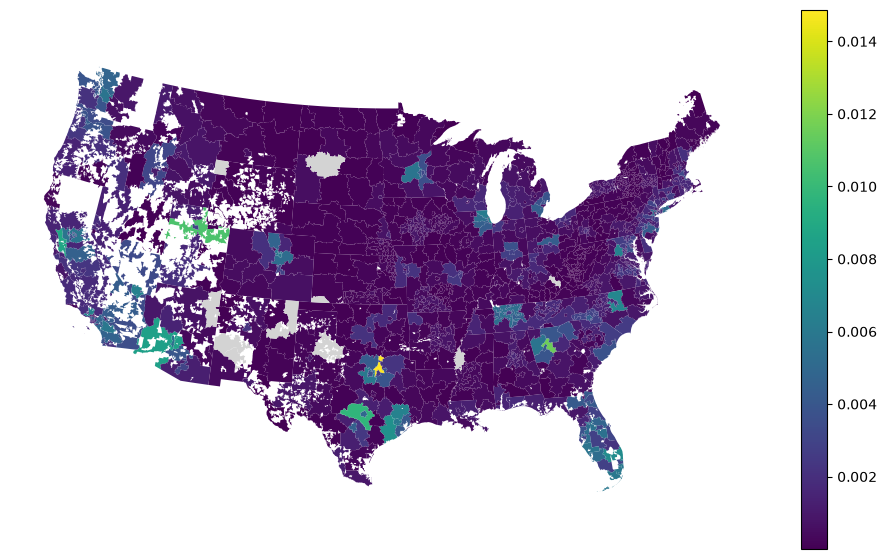

In [66]:
upb = df_orig.groupby(["postal_code", "vintage"])["UPB"].sum().unstack("vintage")
share = upb / upb.sum() 

g = z3.join(share).to_crs(5070)
g = g[~g.index.str[:2].isin(["00", "96", "99"])]   # fuzzy drop of non-continental states
ax = g.plot(column=2022, cmap="viridis", legend=True, figsize=(12, 7),
            missing_kwds={"color": "lightgrey"})
ax.set_axis_off()

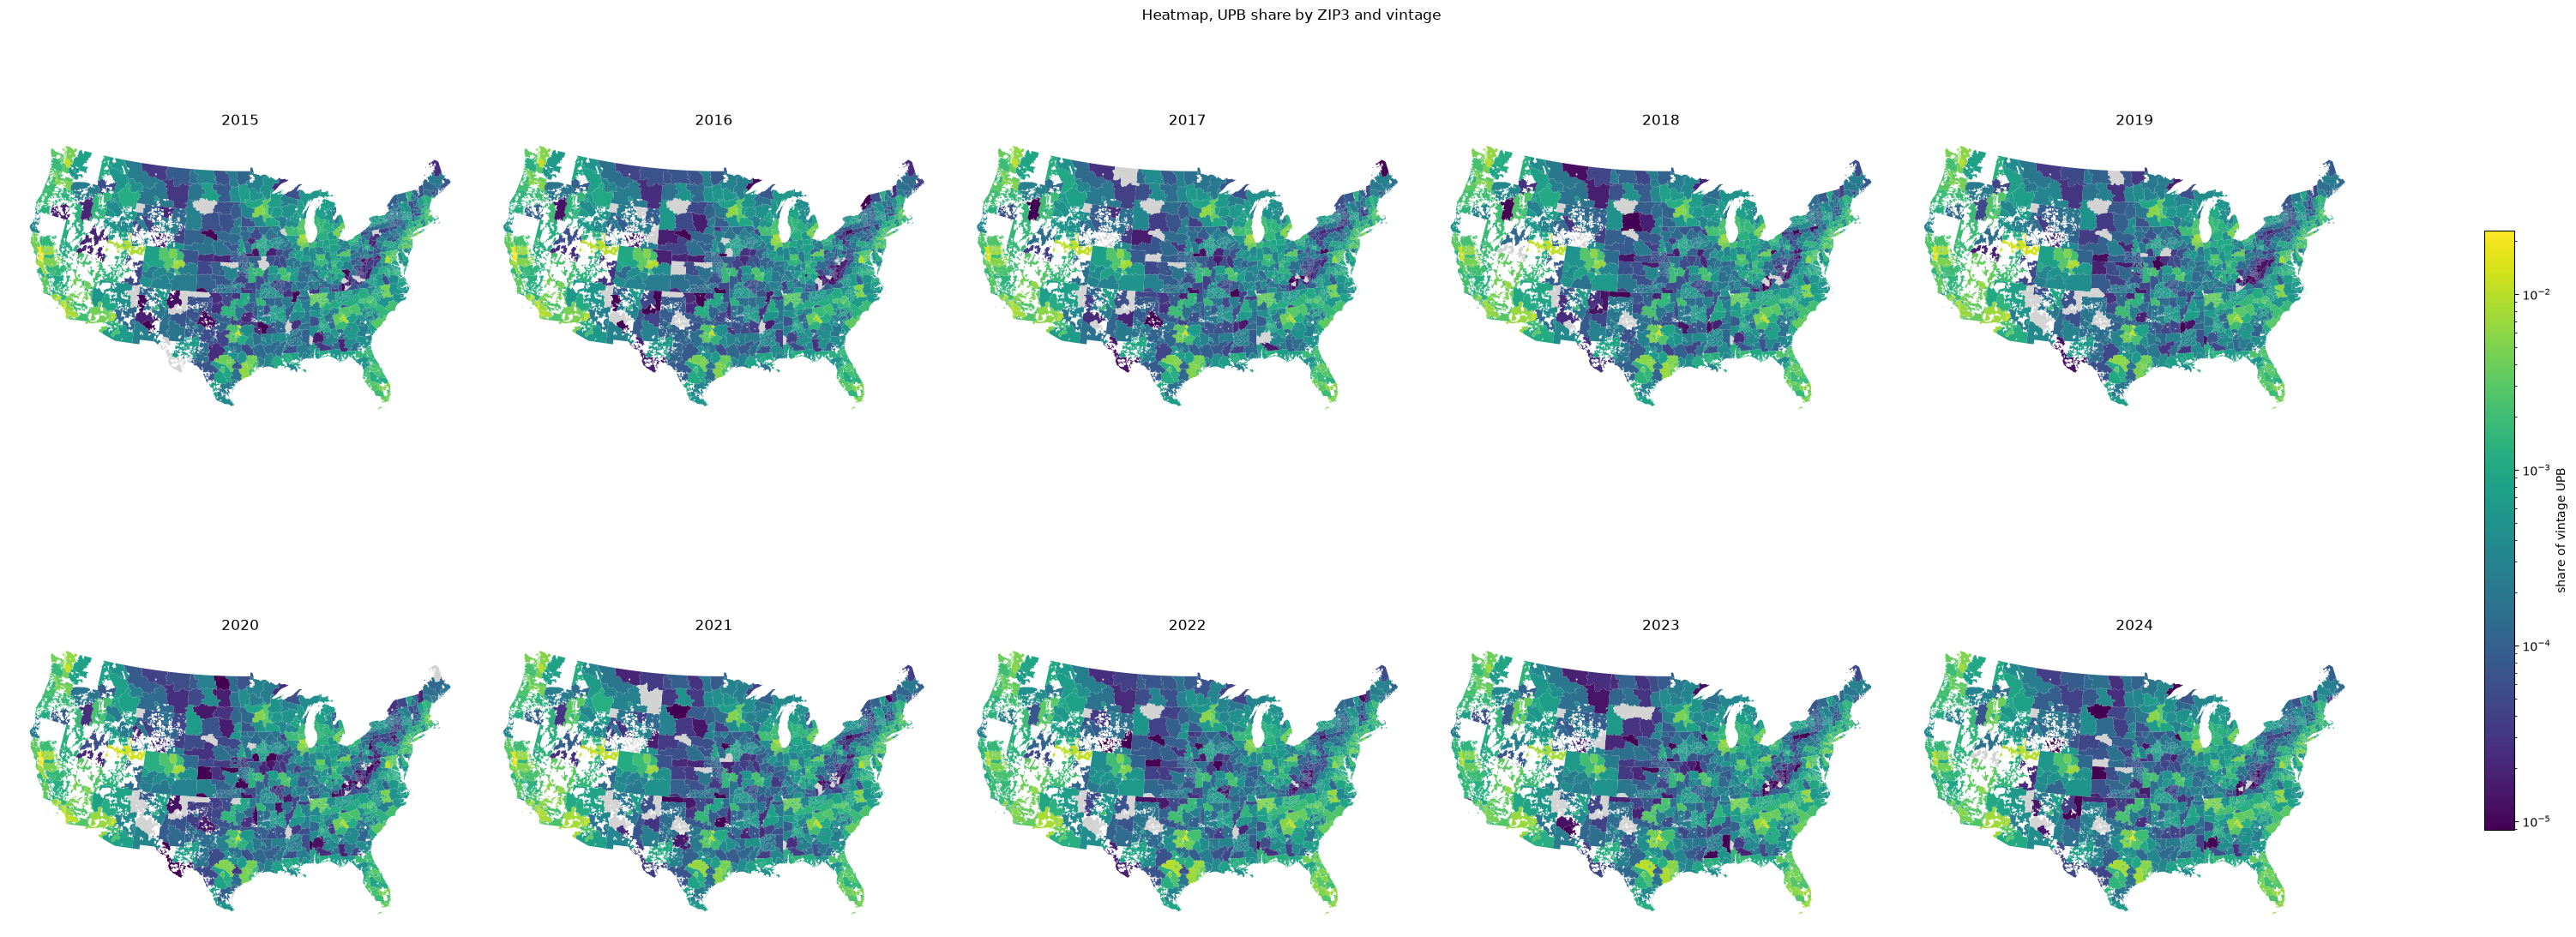

In [67]:
from matplotlib.colors import LogNorm
from matplotlib.colors import TwoSlopeNorm

vals = g[share.columns].stack()
norm = LogNorm(vmin=vals[vals > 0].quantile(0.01), vmax=vals.max())

fig, axes = plt.subplots(2, 5, figsize=(30, 12),constrained_layout=True)
fig.suptitle('Heatmap, UPB share by ZIP3 and vintage')
for ax, v in zip(axes.flat, share.columns):
    g.plot(column=v, cmap="viridis", norm=norm, ax=ax,
           missing_kwds={"color": "lightgrey"})
    ax.set_title(v); ax.set_axis_off()
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"),
             ax=axes, shrink=0.6, label="share of vintage UPB")

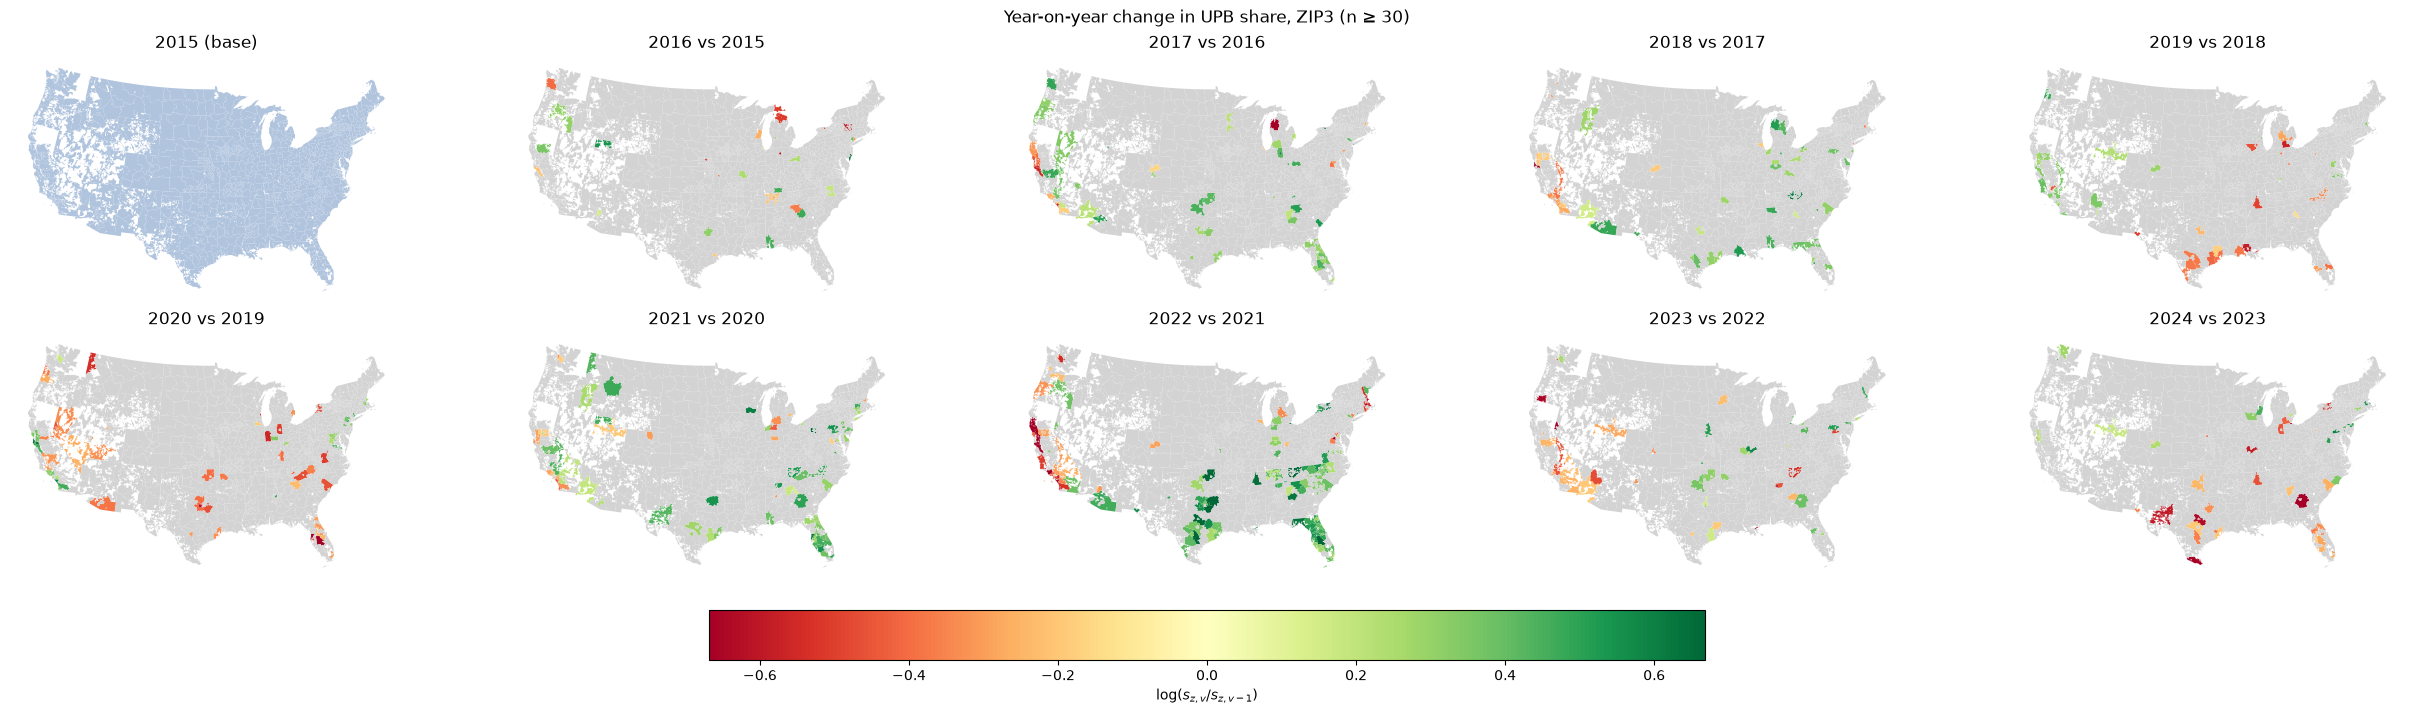

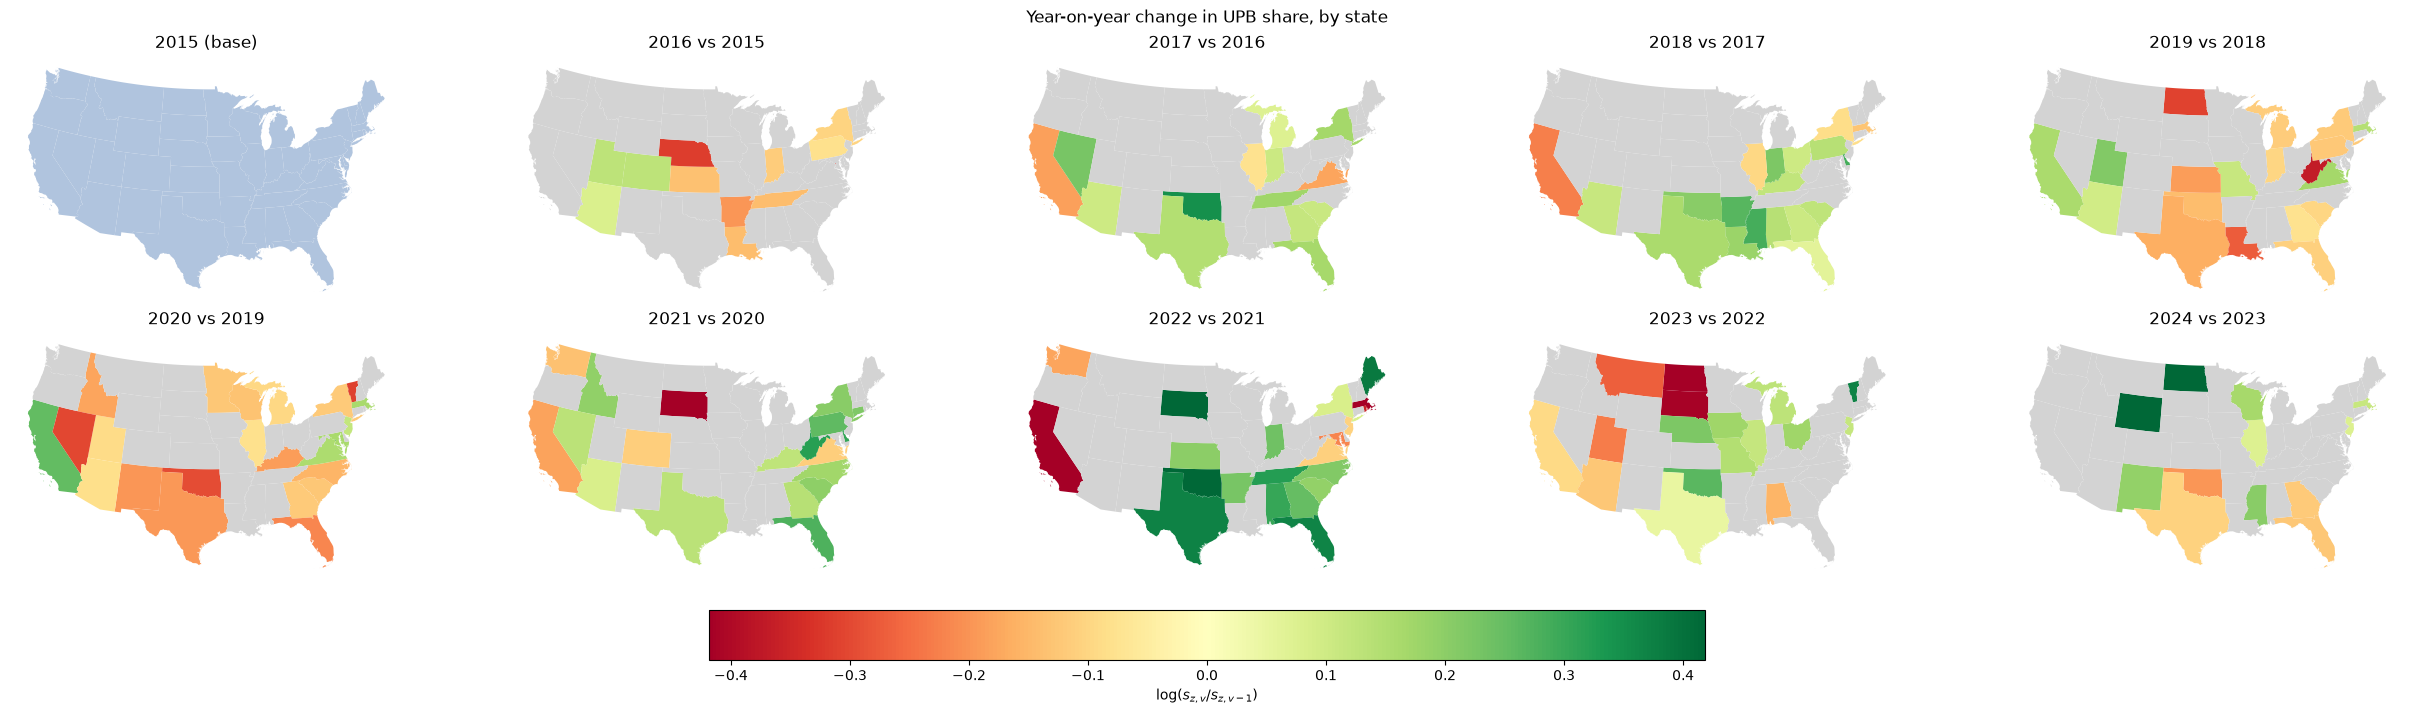

In [ ]:
def log_change(df, key, min_n=30, z=2.0):
    """log(s_v / s_{v-1}) of UPB share per area.
    NaN where either year has < min_n loans, or |r| < z * sqrt(1/n_v + 1/n_{v-1}). to avoid noise"""
    upb = df.groupby([key, "vintage"])["UPB"].sum().unstack("vintage")
    n = df.groupby([key, "vintage"]).size().unstack("vintage").fillna(0)
    s = upb / upb.sum()
    yrs = sorted(s.columns)
    n_now, n_prev = n[yrs[1:]].to_numpy(), n[yrs[:-1]].to_numpy()
    with np.errstate(divide="ignore", invalid="ignore"):
        r = np.log(s[yrs[1:]].to_numpy() / s[yrs[:-1]].to_numpy())
        se = np.sqrt(1 / n_now + 1 / n_prev)
    ok = (n_now >= min_n) & (n_prev >= min_n) & (np.abs(r) >= z * se)
    return pd.DataFrame(np.where(ok, r, np.nan), index=s.index, columns=yrs[1:])

def plot_changes(gdf, r, title):
    g2 = gdf[["geometry"]].join(r)
    lim = np.nanquantile(np.abs(r.to_numpy()), 0.95)
    norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    fig, axes = plt.subplots(2, 5, figsize=(25, 7), constrained_layout=True)
    g2.plot(ax=axes.flat[0], color="lightsteelblue")
    axes.flat[0].set_title(f"{r.columns[0] - 1} (base)")
    for ax, v in zip(axes.flat[1:], r.columns):
        g2.plot(column=v, ax=ax, cmap="RdYlGn", norm=norm,
                missing_kwds={"color": "lightgrey"})
        ax.set_title(f"{v} vs {v - 1}")
    for ax in axes.flat:
        ax.set_axis_off()
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="RdYlGn"), ax=axes,
                 orientation="horizontal", shrink=0.4,
                 label=r"$\log(s_{z,v}/s_{z,v-1})$")
    fig.suptitle(title)
    return fig

# ZIP3
r_z3 = log_change(df_orig, "postal_code", min_n=30)
plot_changes(g, r_z3, "Year-on-year change in UPB share, ZIP3 (n ≥ 30)")

# State level
states = (gpd.read_file("../data/cb_2020_us_state_500k.zip")
            .set_index("STUSPS"))
states = states[~states.index.isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])].to_crs(5070)
r_st = log_change(df_orig, "property_state", min_n=30)
plot_changes(states, r_st, "Year-on-year change in UPB share, by state")
plt.show()

In [69]:
top = share.mean(axis=1).nlargest(15)
top.to_frame("avg_share").join(
    df_orig.groupby("postal_code")["property_state"].agg(lambda x: x.mode()[0]))

,avg_share,property_state
postal_code,,
945,0.015502,CA
750,0.013479,TX
840,0.010735,UT
300,0.010344,GA
852,0.009750,AZ
980,0.009617,WA
926,0.008669,CA
917,0.008593,CA
913,0.008495,CA


# Discrete Metrics, Loan purpose, occupancy type etc

In [91]:
units= df_orig.groupby("vintage")["n_units"].value_counts(normalize=True).unstack(1)
units

n_units,1,2,3,4
vintage,,,,
2015,0.97856,0.01478,0.00366,0.00300
2016,0.97950,0.01412,0.00338,0.00300
2017,0.97360,0.01834,0.00432,0.00374
2018,0.97628,0.01686,0.00392,0.00294
2019,0.97884,0.01530,0.00348,0.00238
2020,0.98278,0.01238,0.00274,0.00210
2021,0.98108,0.01356,0.00308,0.00228
2022,0.97562,0.01766,0.00406,0.00266
2023,0.97852,0.01594,0.00350,0.00204


<Axes: title={'center': 'Decline of 4-unit properties'}, xlabel='Vintage', ylabel='Proportion'>

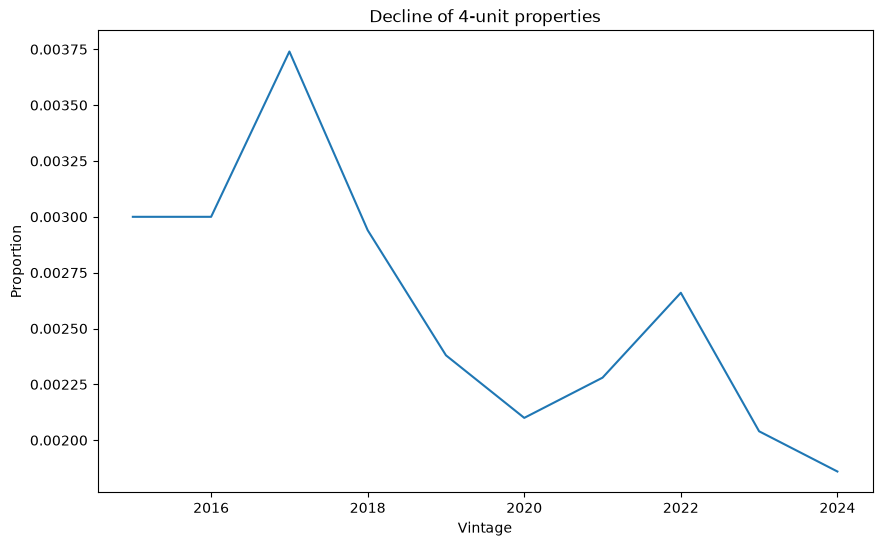

In [90]:
units[4].plot(title="Decline of 4-unit properties", xlabel="Vintage", ylabel="Proportion", figsize=(10, 6))

<Axes: title={'center': 'Loan Purpose Distribution by Vintage'}, xlabel='Vintage', ylabel='Percentage'>

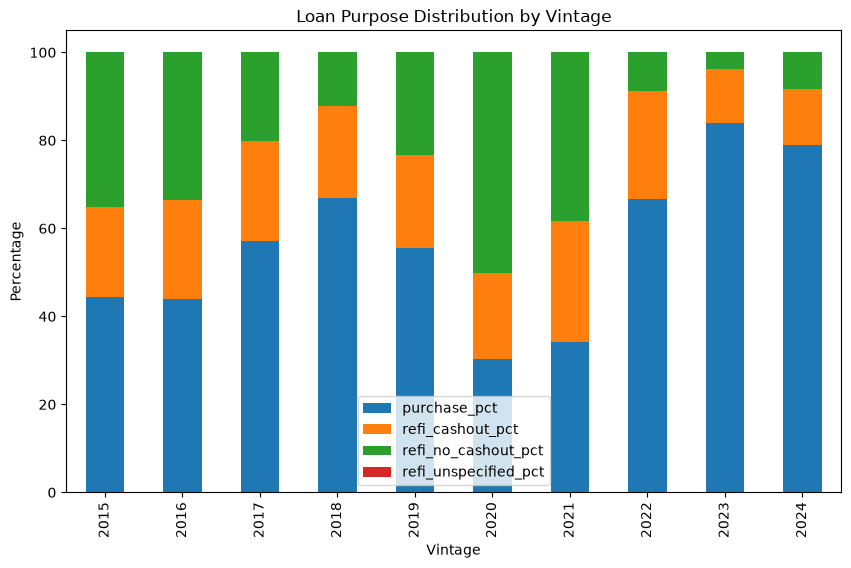

In [107]:
purpose = db.sql("""
    SELECT vintage,
           COUNT(*) FILTER (WHERE loan_purpose = 'P') AS purchase_count,
           COUNT(*) FILTER (WHERE loan_purpose = 'C') AS refi_cashout_count,
           COUNT(*) FILTER (WHERE loan_purpose = 'N') AS refi_no_cashout_count,
           COUNT(*) FILTER (WHERE loan_purpose = 'R') AS refi_unspecified_count,
           COUNT(*) FILTER (WHERE loan_purpose IS NULL
                             OR loan_purpose NOT IN ('P','C','N','R')) AS other_count,
           100.0 * AVG((loan_purpose = 'P')::INT) AS purchase_pct,
           100.0 * AVG((loan_purpose = 'C')::INT) AS refi_cashout_pct,
           100.0 * AVG((loan_purpose = 'N')::INT) AS refi_no_cashout_pct,
           100.0 * AVG((loan_purpose = 'R')::INT) AS refi_unspecified_pct
    FROM df_orig
    GROUP BY vintage
    ORDER BY vintage
""").df()
purpose.plot(x="vintage", y=["purchase_pct", "refi_cashout_pct", "refi_no_cashout_pct", "refi_unspecified_pct"],
             kind="bar", stacked=True, figsize=(10, 6), title="Loan Purpose Distribution by Vintage", xlabel="Vintage", ylabel="Percentage")

# Performance data

In [4]:
perf = {}
for year in range(2015, 2025):
    path = f"../data/sample_{year}/sample_perf_{year}.txt"
    perf[year] = pd.read_csv(
        path, sep="|", names=columns_perf, header=None,
        dtype=dict.fromkeys(perf_str, str),
    )

df_perf = pd.concat(
    (d.assign(vintage=y) for y, d in perf.items()),
    ignore_index=True,
)

/var/folders/_f/7jxbkdnj68z9vspy512w5bzm0000gn/T/ipykernel_15939/2241082607.py:4: DtypeWarning: Columns (7,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  perf[year] = pd.read_csv(
/var/folders/_f/7jxbkdnj68z9vspy512w5bzm0000gn/T/ipykernel_15939/2241082607.py:4: DtypeWarning: Columns (7,23,24) have mixed types. Specify dtype option on import or set low_memory=False.
  perf[year] = pd.read_csv(
/var/folders/_f/7jxbkdnj68z9vspy512w5bzm0000gn/T/ipykernel_15939/2241082607.py:4: DtypeWarning: Columns (7,23) have mixed types. Specify dtype option on import or set low_memory=False.
  perf[year] = pd.read_csv(
/var/folders/_f/7jxbkdnj68z9vspy512w5bzm0000gn/T/ipykernel_15939/2241082607.py:4: DtypeWarning: Columns (7,23) have mixed types. Specify dtype option on import or set low_memory=False.
  perf[year] = pd.read_csv(
/var/folders/_f/7jxbkdnj68z9vspy512w5bzm0000gn/T/ipykernel_15939/2241082607.py:4: DtypeWarning: Columns (7,23) have mixed types. Specify dtype